# 拟合与最优化 ― optimize 模块

## 本章要学什么

要把实验数据拟合成公式、或者找出满足条件的值，靠手算解方程是很吃力的，`optimize` 模块就用数值方法来完成这类计算。

- 用 `fsolve()` 解非线性联立方程
- 用 `least_squares()` 与 `curve_fit()` 把曲线拟合到数据上
- 用损失函数抑制异常值的影响
- 用 `minimize()` 寻找函数的极小值
- 用 `basinhopping()` 寻找全局最小值
- 折线拟合、悬链线、最速降线这几个应用

In [1]:
from matplotlib import pyplot as plt
import helper.matplotlib
import numpy as np
from scipy import optimize

## 解非线性方程

`fsolve()` 用数值方法解非线性方程，调用形式是 `fsolve(func, x0)`，其中 `func` 返回方程的误差、参数 `x` 是解的候选值数组，而 `x0` 是解的初始值。先看下面这个联立方程。

$$
\begin{align}
f1(u1,u2,u3) &= 0 \\ 
f2(u1,u2,u3) &= 0 \\ 
f3(u1,u2,u3) &= 0
\end{align}
$$

这种情况下，`func` 可以写成下面这样。

```python
def func(x):
    u1,u2,u3 = x
    return [f1(u1,u2,u3), f2(u1,u2,u3), f3(u1,u2,u3)]
```

实际来解下面这组方程。

$$
\begin{align}
5 x_1 + 3 &= 0 \\ 
4 x_0^2 - 2 \sin(x_1 x_2) &= 0 \\ 
x_1 x_2 - 1.5 &= 0
\end{align}
$$

In [2]:
from math import sin, cos
from scipy import optimize


def f(x):  #❶
    x0, x1, x2 = x.tolist()  #❷
    return [5 * x1 + 3, 4 * x0 * x0 - 2 * sin(x1 * x2), x1 * x2 - 1.5]


# f 计算方程的误差，[1,1,1] 是未知量的初始值
result = optimize.fsolve(f, [1, 1, 1])  #❸
print(result, f(result))

[-0.70622057 -0.6        -2.5       ] [0.0, -9.126033262418787e-14, 5.329070518200751e-15]


❶ `f()` 返回方程的误差，参数 `x` 是解的候选值；`fsolve()` 调用 `f()` 时传进来的 `x` 是数组。❷ 这里先用 `tolist()` 把它转成 Python 浮点数的列表，再用 `math` 模块的函数计算，因为只算一个数值时 Python 的 `float` 比 NumPy 的浮点数更快。❸ 最后把计算误差的函数与解的初始值交给 `fsolve()`。

`fsolve()` 在过程中会计算各个未知量的偏微分，把这些偏微分排成的矩阵就是雅可比矩阵。当未知量很多、而每个方程里出现的未知量很少时(也就是雅可比矩阵稀疏时)，把计算雅可比矩阵的函数传进去会更快。

:::{admonition} 雅可比矩阵
:class: note
雅可比矩阵是把一阶偏微分按某个顺序排成的矩阵，也可以把它理解成把可微的方程在给定点附近做线性近似的结果，相当于多变量函数的导数。例如函数 $f1$、$f2$、$f3$ 与未知量 $u1$、$u2$、$u3$ 的雅可比矩阵如下。

$$ 
\begin{bmatrix}
\dfrac{\partial f1}{\partial u1} & \dfrac{\partial f1}{\partial u2} & \dfrac{\partial f1}{\partial u3} \\[9pt]
\dfrac{\partial f2}{\partial u1} & \dfrac{\partial f2}{\partial u2} & \dfrac{\partial f2}{\partial u3} \\[9pt]
\dfrac{\partial f3}{\partial u1} & \dfrac{\partial f3}{\partial u2} & \dfrac{\partial f3}{\partial u3} \\
\end{bmatrix}
$$
:::

把雅可比矩阵传进去，解同一组方程：❶ 计算雅可比矩阵的 `j()` 同样以未知量的数组 `x` 为参数，返回 `x` 处的雅可比矩阵；❷ 把 `j()` 传给 `fprime`。这个例子里未知量很少，所以即使传了雅可比矩阵也不会变快。

In [3]:
def j(x):  #❶
    x0, x1, x2 = x.tolist()
    return [
        [0, 5, 0],
        [8 * x0, -2 * x2 * cos(x1 * x2), -2 * x1 * cos(x1 * x2)],
        [0, x2, x1],
    ]


result = optimize.fsolve(f, [1, 1, 1], fprime=j)  #❷
print(result, f(result))

[-0.70622057 -0.6        -2.5       ] [0.0, -9.126033262418787e-14, 5.329070518200751e-15]


## 最小二乘拟合

假设有实验数据 $(x_i, y_i)$，并且已知它们满足 $y_i = f(x_i)$ 的关系，要由这些信息定出函数 $f(x)$ 的参数。例如 $f(x)$ 是直线 $f(x) = k x+b$ 时，要定的就是 $k$ 和 $b$。

把待定的参数记作 $\mathbf{p}$，目标就是找出让下面这个 $S(\mathbf{p})$ 最小的 $\mathbf{p}$。

$$S(\mathbf{p}) = \sum_{i=1}^m [y_i - f(x_i, \mathbf{p}) ]^2$$

这个办法叫最小二乘法(least-square fitting)，在 `optimize` 模块里用 `least_squares()` 就能算，只要把返回误差的函数和参数的初始值交给它。下面的程序把一条直线拟合到数据上。

In [4]:
import numpy as np

X = np.array([8.19, 2.72, 6.39, 8.71, 4.7, 2.66, 3.78])
Y = np.array([7.01, 2.78, 6.47, 6.71, 4.1, 4.23, 4.05])


def residuals(p):  #❶
    "计算以 p 为参数的直线与原数据的误差"
    k, b = p
    return Y - (k * X + b)


# least_squares 最小化 residuals() 输出的平方和，参数初始值是 [1,0]
r = optimize.least_squares(residuals, [1, 0])  #❷
k, b = r.x
print("k =", k, "b =", b)

k = 0.6134953448328452 b = 1.7940925666541077


下图左边是原始数据、拟合出的直线以及两者的差：❶ `residuals()` 的参数 `p` 就是直线的参数，函数返回数据与直线的差，图上数据点到直线的竖直距离就是误差；❷ `least_squares()` 要最小化的就是这个误差的平方和，也就是图中红色长方形的面积之和。

从 $S$ 的式子可以看出，拟合直线时误差平方和是参数 $k$ 与 $b$ 的二次式。所以能像右图那样把误差平方和与两个参数的关系画成曲面。曲面上的红点就是最小点，它对应的 $k$ 与 $b$ 就是 `least_squares()` 的结果。

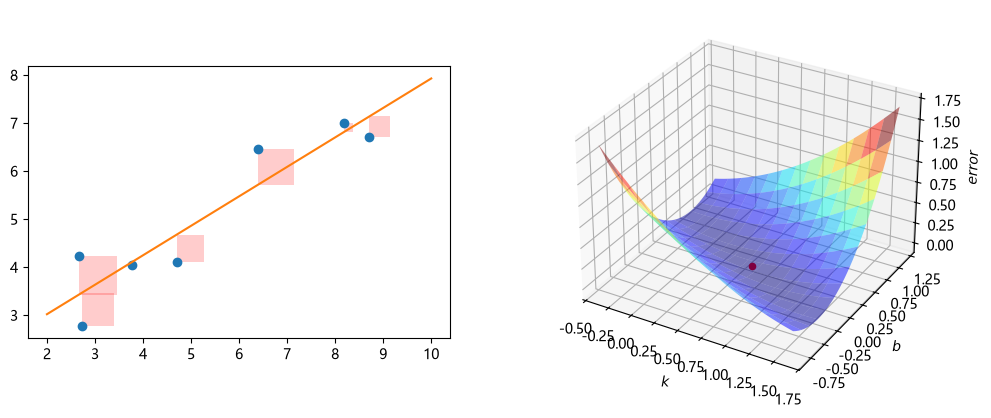

In [5]:
scale_k = 1.0
scale_b = 10.0
scale_error = 1000.0


def S(k, b):
    """计算直线 y=k*x+b 与数据 X, Y 的误差平方和。"""
    error = np.zeros(k.shape)
    for x, y in zip(X, Y):
        error += (y - (k * x + b)) ** 2
    return error


ks, bs = np.mgrid[k - scale_k : k + scale_k : 40j, b - scale_b : b + scale_b : 40j]
error = S(ks, bs) / scale_error

from matplotlib.patches import Rectangle

fig = plt.figure(figsize=(12, 5))

ax1 = plt.subplot(121)
ax1.plot(X, Y, "o")                        # 原始数据
X0 = np.linspace(2, 10, 3)
Y0 = k * X0 + b
ax1.plot(X0, Y0)                            # 拟合出的直线
for x, y in zip(X, Y):
    y2 = k * x + b
    rect = Rectangle((x, y), abs(y - y2), y2 - y, facecolor="red", alpha=0.2)
    ax1.add_patch(rect)                     # 用长方形表示误差
ax1.set_aspect("equal")

ax2 = fig.add_subplot(122, projection="3d")
ax2.plot_surface(ks, bs / scale_b, error, rstride=3, cstride=3, cmap="jet", alpha=0.5)
ax2.scatter([k], [b / scale_b], [S(k, b) / scale_error], c="r", s=20)
ax2.set_xlabel("$k$")
ax2.set_ylabel("$b$")
ax2.set_zlabel("$error$")
plt.show()

接下来把曲线拟合到正弦波的数据上。

真实参数: [10, 0.34, 0.5235987755982988]
拟合参数 [10.25218748  0.3423992   0.50817423]


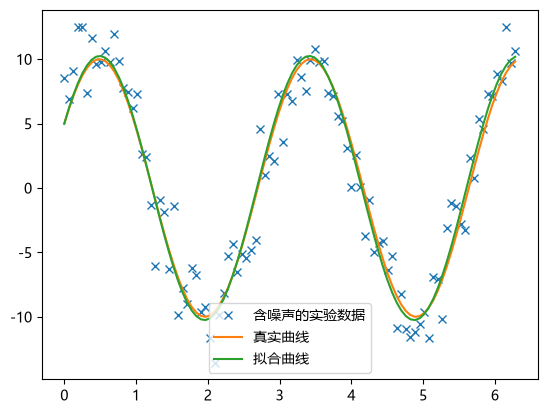

In [6]:
def func(x, p):  #❶
    """
    用于拟合数据的函数：A*sin(2*pi*k*x + theta)
    """
    A, k, theta = p
    return A * np.sin(2 * np.pi * k * x + theta)


def residuals(p, y, x):  #❷
    """
    实验数据 x、y 与拟合函数之差，p 是拟合所需的系数
    """
    return y - func(x, p)


x = np.linspace(0, 2 * np.pi, 100)
A, k, theta = 10, 0.34, np.pi / 6  # 真实数据的函数参数
y0 = func(x, [A, k, theta])  # 真实数据
# 加了噪声的实验数据
np.random.seed(0)
y1 = y0 + 2 * np.random.randn(len(x))  #❸

p0 = [7, 0.40, 0]  # 最初的猜测值

# 用 least_squares 拟合数据
# residuals 是计算误差的函数
# p0 是拟合参数的初始值
# args 是要拟合的实验数据
plsq = optimize.least_squares(residuals, p0, args=(y1, x))  #❹

print("真实参数:", [A, k, theta])
print(
    "拟合参数", plsq.x
)  # 拟合实验数据之后的参数
plt.plot(x, y1, "x", label="含噪声的实验数据")
plt.plot(x, y0, label="真实曲线")
plt.plot(x, func(x, plsq.x), label="拟合曲线")
plt.legend(loc="best");

❶ 要拟合的函数 `func()` 是正弦函数，参数 `p` 是振幅、频率和相位这 3 个。❷ `residuals()` 返回数据 `y` 与 `func()` 的值之差。❸ 实验数据 `y1` 是在正弦波 `y0` 上加了噪声得到的。

❹ 用 `least_squares()` 把曲线拟合到 `(x, y1)` 上，定出 `A`、`k`、`theta`。与直线的例子不同，这里把 `(y1, x)` 传给了 `args`，`least_squares()` 会把这些额外的参数再传给 `residuals()`。因此 `residuals()` 接收 3 个参数，其中 `p` 是正弦函数的参数，`y` 与 `x` 是数据。

如果只是拟合一条一维曲线，用 `curve_fit()` 更简单。下面的例子用 `curve_fit()` 拟合同样的正弦波，待优化的参数直接作为函数的参数传入。

In [7]:
def func2(x, A, k, theta):
    return A * np.sin(2 * np.pi * k * x + theta)


popt, _ = optimize.curve_fit(func2, x, y1, p0=p0)
print(popt)

[10.25218748  0.3423992   0.50817424]


如果频率的初始值离真值很远，拟合出的频率有时不会收敛到正确的值：下面的例子里把频率的初始值取成 1。于是 `curve_fit()` 并没有收敛到真实的参数。遇到这种情况，可以换别的办法先估计频率，或者改用全局最优化；后面的小节会用全局最优化拟合同一份数据。

In [8]:
popt, _ = optimize.curve_fit(func2, x, y1, p0=[10, 1, 0])
print("真实参数:", [A, k, theta])
print("拟合参数", popt)

真实参数: [10, 0.34, 0.5235987755982988]
拟合参数 [ 0.7109346   1.02074589 -0.1277675 ]


## 抑制异常值的影响

最小二乘法把误差平方之后再相加，所以容易受异常值影响：数据里一旦有异常值，它的误差会明显改变目标函数，算法就会努力去减小那部分误差，结果拟合出的参数偏离真值。`least_squares()` 提供了指定损失函数的 `loss` 以及用于调整的 `f_scale`，把它们改一改就能改变误差与目标函数的关系，从而抑制异常值的影响。

下面例子里的 `func()` 是衰减振动 $f(t) = A e^{-\sigma t} \sin(\omega t)$，数据 `y_noise` 里既有噪声，也有几个异常值，`curve_fit()` 的结果被异常值带偏，与真值差得很远。

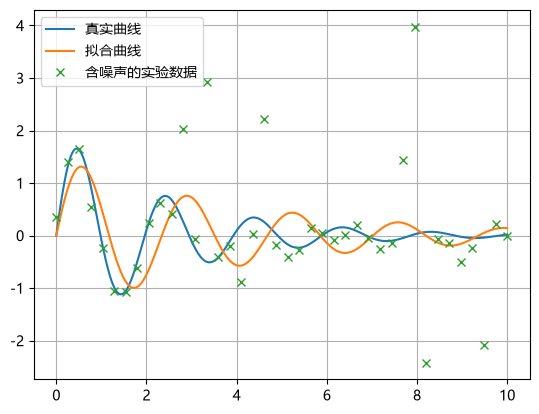

In [9]:
def func(t, A, sigma, omega):
    y = A * np.exp(-sigma * t) * np.sin(omega * t)
    return y


def random_noise(noise, n_outliers, n):
    error = noise * np.random.randn(n)
    outliers = np.random.randint(0, n, n_outliers)
    error[outliers] *= 10
    return error


t = np.linspace(0, 10, 40)
args = 2, 0.4, 3.2
np.random.seed(3)
y_noise = func(t, *args) + random_noise(0.2, 8, len(t))
args_fit, _ = optimize.curve_fit(func, t, y_noise)

t2 = np.linspace(0, 10, 400)
plt.plot(t2, func(t2, *args), label="真实曲线")
plt.plot(t2, func(t2, *args_fit), label="拟合曲线")
plt.plot(t, y_noise, "x", label="含噪声的实验数据")
plt.legend()
plt.grid();

`least_squares()` 可用的损失函数有 linear、soft_l1、huber、cauchy、arctan 等，式子如下，图形见下左图，图中曲线画的是 $\rho(x^2)$。除 linear 之外，这些函数的值增长得比 linear 慢，所以对大误差的异常值不那么敏感。

* linear：$\rho(z) = z$，
* soft_l1：$\rho(z) = 2 (\sqrt{1 + z} - 1)$
* huber：$\rho(x)=\begin{cases}
z &{\text{if }}z\leq 1\\
2 \sqrt{z} -1 &{\text{if }} z > 1\\
\end{cases}
$
* cauchy: $\rho(z) =\ln(1 + z)$
* arctan: $\rho(z) = \arctan(z)$

使用损失函数之后，`least_squares()` 的目标函数就变成下面这样。

$$S(\mathbf{p}) = \sum_{i=1}^m \rho((y_i - f(x_i, \mathbf{p}))^2)$$

对 linear 之外的损失函数，可以用 `f_scale` 指定调整系数，损失函数按下面的式子计算，其中 $C$ 就是 `f_scale`。

$$\rho'(e^2) = C^2 \cdot \rho(\frac{e^2}{C^2})$$

下右图是 $C$ 与损失函数的关系：$C$ 在 0 到 1 之间时，$\rho'$ 接近 $\rho$(黑色虚线)；$C$ 大于 1 时，$\rho'$ 接近 linear(黑色实线)。

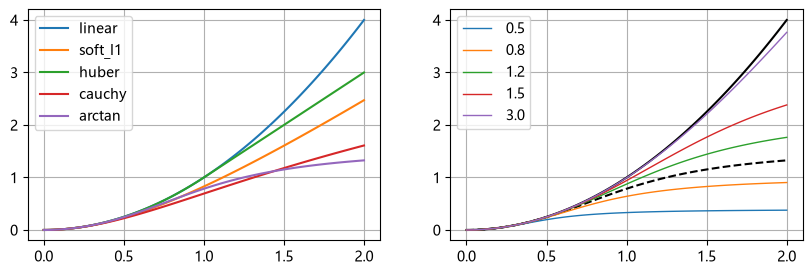

In [10]:
def linear(z):
    return z


def soft_l1(z):
    return 2 * ((1 + z) ** 0.5 - 1)


def huber(z):
    return np.where(z <= 1, z, 2 * z**0.5 - 1)


def cauchy(z):
    return np.log(1 + z)


def arctan(z):
    return np.arctan(z)


fig, axes = plt.subplots(1, 2, figsize=(10, 3))
z = np.linspace(0, 2, 100)
for _func in (linear, soft_l1, huber, cauchy, arctan):
    y = _func(z**2)
    axes[0].plot(z, y, label=_func.__name__)
axes[0].legend()


def f_scale(func, z, c):
    return c**2 * func(z**2 / c**2)


axes[1].plot(z, z**2, "k")
axes[1].plot(z, arctan(z**2), "k--")
for c in (0.5, 0.8, 1.2, 1.5, 3.0):
    axes[1].plot(z, f_scale(arctan, z, c), label="{:4.1f}".format(c), linewidth=1)
axes[1].legend()

for ax in axes:
    ax.grid(True);

下面的例子把损失函数指定为 `soft_l1`、把 `f_scale` 指定为 0.3 来拟合，可以看到拟合出的曲线已经贴近真实曲线。

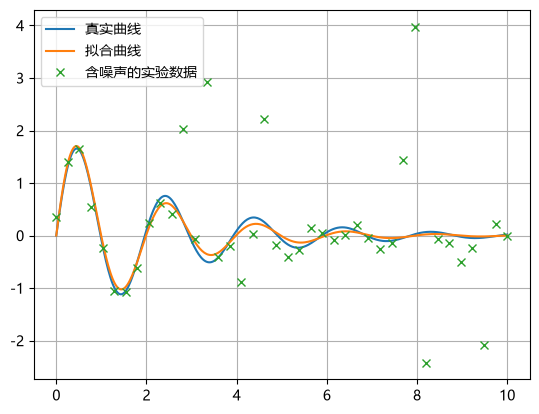

In [11]:
def err(pars):
    return func(t, *pars) - y_noise


res = optimize.least_squares(err, [1, 1, 1], loss="soft_l1", f_scale=0.3)

plt.plot(t2, func(t2, *args), label="真实曲线")
plt.plot(t2, func(t2, *res.x), label="拟合曲线")
plt.plot(t, y_noise, "x", label="含噪声的实验数据")
plt.legend()
plt.grid();

## 求函数的极小值

`optimize` 里有很多寻找函数最小值的算法，例如 Nelder-Mead、Powell、CG、BFGS、Newton-CG、L-BFGS-B 等。这里确认它们各自是怎样逼近最小值的，目标函数如下。

$$f(x,y) = (1-x)^2 + 100(y-x^2)^2$$

这就是所谓的 Rosenbrock 函数，常用它来检验最小化算法的收敛速度：这个函数的谷底非常平坦，进入谷底很容易，但在谷底里找出最小点却很难。从式子上看，最小值是 0，位置在 (1, 1)。

为了算得又快又准，有些算法可以接收 `fprime`(目标函数的偏导数)，$f(x,y)$ 的偏导数如下。

$$\frac{\partial f}{\partial x}= -2 + 2x - 400x(y-x^2)$$
$$\frac{\partial f}{\partial y}= 200y - 200x^2$$

Newton-CG 还需要海森矩阵，也就是把二阶偏导数排成的方阵。函数 $f(x_1, x_2, \dots, x_n)$ 的海森矩阵定义如下。

$$\begin{bmatrix} 
\frac{\partial^2 f}{\partial x_1^2} & 
\frac{\partial^2 f}{\partial x_1 \partial x_2} &
\cdots & 
\frac{\partial^2 f}{\partial x_1 \partial x_n} \\ 
\frac{\partial^2 f}{\partial x_2 \partial x_1} &
\frac{\partial^2 f}{\partial x_2^2} &
\cdots &
\frac{\partial^2 f}{\partial x_2 \partial x_n} \\
\vdots &
\vdots &
\ddots &
\vdots \\
\frac{\partial^2 f}{\partial x_n \partial x_1} &
\frac{\partial^2 f}{\partial x_n \partial x_2} &
\cdots &
\frac{\partial^2 f}{\partial x_n^2}
\end{bmatrix}$$

这个例子的海森矩阵是二阶矩阵。

$$\begin{bmatrix} 2(600x^2 - 200 y + 1) & -400x \\
                  -400x & 200 \end{bmatrix}$$

下面的程序用 6 种算法求 $f(x,y)$ 的最小值。从输出可以看到，有些算法收敛要花不少时间，而有些算法借助导数的信息很快就能到达最小点。

In [12]:
import warnings

warnings.filterwarnings("ignore")   # 这里不显示最优化的收敛警告

In [13]:
def target_function(x, y):
    return (1 - x) ** 2 + 100 * (y - x**2) ** 2


class TargetFunction(object):

    def __init__(self):
        self.f_points = []
        self.fprime_points = []
        self.fhess_points = []

    def f(self, p):
        x, y = p.tolist()
        z = target_function(x, y)
        self.f_points.append((x, y))
        return z

    def fprime(self, p):
        x, y = p.tolist()
        self.fprime_points.append((x, y))
        dx = -2 + 2 * x - 400 * x * (y - x**2)
        dy = 200 * y - 200 * x**2
        return np.array([dx, dy])

    def fhess(self, p):
        x, y = p.tolist()
        self.fhess_points.append((x, y))
        return np.array([[2 * (600 * x**2 - 200 * y + 1), -400 * x], [-400 * x, 200]])


def fmin_demo(method):
    target = TargetFunction()
    init_point = (-1, -1)
    res = optimize.minimize(
        target.f,
        init_point,
        method=method,
        jac=target.fprime,
        hess=target.fhess,
    )
    return res, [
        np.array(points)
        for points in (target.f_points, target.fprime_points, target.fhess_points)
    ]


methods = ("Nelder-Mead", "Powell", "CG", "BFGS", "Newton-CG", "L-BFGS-B")
for method in methods:
    res, (f_points, fprime_points, fhess_points) = fmin_demo(method)
    print(
        f"{method:12s}: min={res['fun']:12g}, "
        f"f count={len(f_points):3d}, "
        f"fprime count={len(fprime_points):3d}, "
        f"fhess count={len(fhess_points):3d}"
    )

Nelder-Mead : min= 5.30934e-10, f count=125, fprime count=  0, fhess count=  0
Powell      : min=           0, f count= 47, fprime count=  0, fhess count=  0
CG          : min= 9.61938e-21, f count= 39, fprime count= 39, fhess count=  0
BFGS        : min= 1.84992e-16, f count= 40, fprime count= 40, fhess count=  0
Newton-CG   : min= 5.22666e-10, f count= 60, fprime count= 60, fhess count= 38
L-BFGS-B    : min=  6.5215e-15, f count= 33, fprime count= 33, fhess count=  0


下图是各算法经过的搜索路径：圆点是调用 `f()` 的位置，颜色表示调用的先后顺序，× 号是调用 `fprime()` 的位置。背景的深浅是二维函数的值，值越大越浅、越小越深；为了看清谷的形状，这里画的是 $\log10(f(x,y))$。

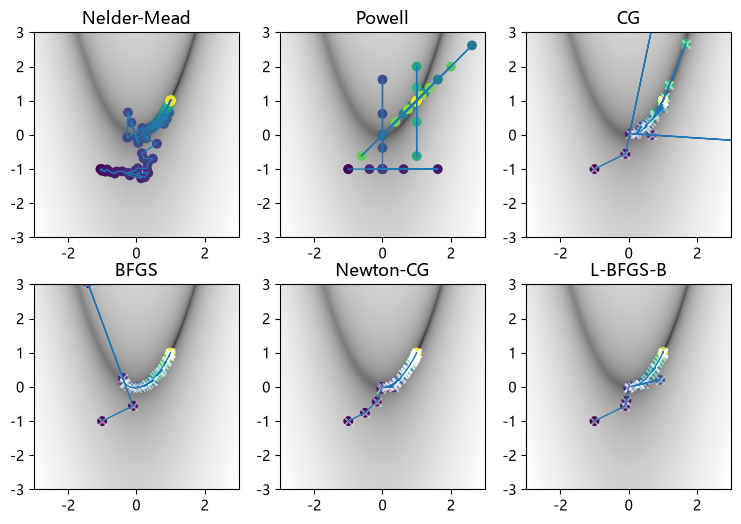

In [14]:
def draw_fmin_demo(f_points, fprime_points, ax):
    xmin, xmax = -3, 3
    ymin, ymax = -3, 3
    Y, X = np.ogrid[ymin:ymax:500j, xmin:xmax:500j]
    Z = np.log10(target_function(X, Y))
    zmin, zmax = np.min(Z), np.max(Z)
    ax.imshow(
        Z, extent=(xmin, xmax, ymin, ymax), origin="lower", aspect="auto", cmap="gray"
    )
    ax.plot(f_points[:, 0], f_points[:, 1], lw=1)
    ax.scatter(
        f_points[:, 0], f_points[:, 1], c=range(len(f_points)), s=50, linewidths=0
    )
    if len(fprime_points):
        ax.scatter(
            fprime_points[:, 0], fprime_points[:, 1], marker="x", color="w", alpha=0.5
        )
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)


import matplotlib as mpl

with mpl.rc_context({"font.size": 10.0}):
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    methods = ("Nelder-Mead", "Powell", "CG", "BFGS", "Newton-CG", "L-BFGS-B")
    for ax, method in zip(axes.ravel(), methods):
        res, (f_points, fprime_points, fhess_points) = fmin_demo(method)
        draw_fmin_demo(f_points, fprime_points, ax)
        ax.set_aspect("equal")
        ax.set_title(method)

## 求全局最小值

到这里的算法都只能找到初始值附近的极小值，而 `optimize` 里也有寻找全局最小值的算法，这里以正弦波的拟合为例。

传给 `least_squares()` 的误差函数返回的是各数据点误差组成的数组，而函数最小化的算法只能最小化一个值。所以这里准备一个返回误差平方和的 `func_error()`。

In [15]:
def func(x, p):
    A, k, theta = p
    return A * np.sin(2 * np.pi * k * x + theta)


def func_error(p, y, x):
    return np.sum((y - func(x, p)) ** 2)


x = np.linspace(0, 2 * np.pi, 100)
A, k, theta = 10, 0.34, np.pi / 6
y0 = func(x, [A, k, theta])
np.random.seed(0)
y1 = y0 + 2 * np.random.randn(len(x))

用 `optimize.basinhopping()` 来找正弦波的 3 个参数：前两个参数与别的最小化函数一样，是目标函数和初始值，由于是全局最优化，初始值怎么选并不太重要；`niter` 是迭代次数，次数越多越容易找到全局最优解。

`basinhopping()` 内部会调用局部的极小化函数，用 `minimizer_kwargs` 指定使用哪种局部算法以及传给它的参数。下面的程序用 L-BFGS-B，并通过 `args` 把 `y1` 与 `x` 传给 `func_error()`。

In [16]:
result = optimize.basinhopping(
    func_error,
    (1, 1, 1),
    niter=10,
    minimizer_kwargs={"method": "L-BFGS-B", "args": (y1, x)},
)
print(result.x)

[10.25218699 -0.34239909  2.63341582]


拟合出的相位与原值不同，但正弦函数是周期函数。所以拟合出的曲线与原数据是重合的，如下图。

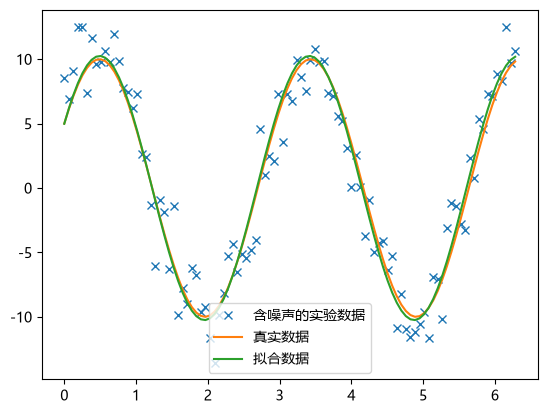

In [17]:
plt.plot(x, y1, "x", label="含噪声的实验数据")
plt.plot(x, y0, label="真实数据")
plt.plot(x, func(x, result.x), label="拟合数据")
plt.legend(loc="best");

## 应用实例

### 用折线拟合

这里说明怎样用最小化的算法把数据点拟合成分段的折线，在计算能力有限的嵌入式系统里，常用折线去近似复杂的曲线。

由 $N$ 条线段构成的折线有 $N+1$ 个点，要确定每个点的 x 坐标与 y 坐标。所以确定整条折线需要 $2(N+1)$ 个参数。

`segments_fit()` 里把参数这样安排：

❶ 把 $N$ 条线段在 x 方向上的长度作为折线的 x 参数，$N+1$ 个点的 y 坐标则是其余的参数，而第一个点的 x 坐标固定为数据 x 坐标的最小值。❷ `bounds` 里放入所有参数的范围：前 $N$ 个大于 0 且小于数据 x 的范围，后 $N+1$ 个写成 `(None, None)`，不加限制。

❸ `func()` 返回折线 $N+1$ 个点的 x 坐标与 y 坐标。❹ `error()` 返回折线与数据点的误差，第 1 项是数据点与折线 y 坐标之差的均方值，第 2 项是折线 x 范围与数据 x 范围之差的平方；正因为有第 2 项，折线的最后一个点才会落在数据 x 坐标的最大处。

In [18]:
def segments_fit(xdata, ydata, n):
    xmin = xdata.min()
    xmax = xdata.max()
    xspan = xmax - xmin

    segments_init = np.full(n, (xmax - xmin) / n)
    y_init = np.zeros(n + 1)
    init = np.r_[segments_init, y_init]  #❶
    bounds = [(0, xmax - xmin)] * len(segments_init) + [(None, None)] * len(y_init)  #❷

    def func(p):  #❸
        segments = p[:n]
        y = p[n:]
        x = np.r_[xmin, segments].cumsum()
        return x, y

    def error(p):  #❹
        x, y = func(p)
        yfit = np.interp(xdata, x, y)
        return np.mean((yfit - ydata) ** 2) + ((x[-1] - x[0]) - xspan) ** 2

    r = optimize.minimize(error, x0=init, method="L-BFGS-B", bounds=bounds)
    return func(r.x)

下面的程序用 `segments_fit()` 拟合两种数据：一种是由 `make_test_data()` 生成的折线数据，另一种是加了噪声的正弦波，结果如下图。

In [19]:
def make_test_data(seg_count, point_count):
    x = np.random.uniform(2, 10, seg_count)
    x = np.cumsum(x)
    x *= 10 / x.max()
    y = np.cumsum(np.random.uniform(-1, 1, seg_count))
    X = np.random.uniform(0, 10, point_count)
    Y = np.interp(X, x, y) + np.random.normal(0, 0.05, point_count)
    return X, Y


x1, y1 = make_test_data(10, 1000)
x2 = np.random.uniform(0, 2 * np.pi, 1000)
y2 = np.sin(x2) + np.random.normal(0, 0.05, x2.shape)

sx1, sy1 = segments_fit(x1, y1, 10)
sx2, sy2 = segments_fit(x2, y2, 10)

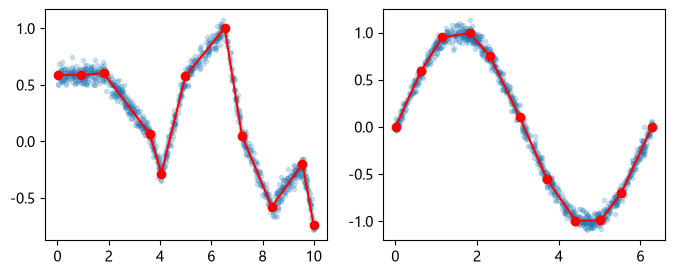

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(x1, y1, ".", alpha=0.2)
axes[0].plot(sx1, sy1, "-or")
axes[1].plot(x2, y2, ".", alpha=0.2)
axes[1].plot(sx2, sy2, "-or");

### 用位置能最小化求悬链线

这里说明怎样用最优化算法把悬链线的位置能降到最小，从而求出它的形状。把绳子的两端固定在同样高度让它垂下，这个形状就是悬链线，曲线用下面的式子表示。

$$y = a\cosh \frac{x}{a}$$
 
其中 $a$ 是决定下垂程度的系数。下面的 `catenary()` 把悬链线的式子做了坐标变换，使它正好通过 (0, 0) 与 (1, 0) 两点，形状如下图。

:::{note}
这条曲线两端的斜率并不为零，所以随着 $a$ 变小，中间会垂得越来越低，而 $a$ 越大形状就越接近水平线。下面要做的，就是在两端固定的前提下，找出真正让位置能最小的那一条。
:::

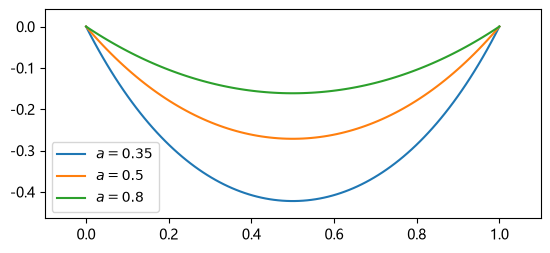

In [21]:
def catenary(x, a):
    return a * np.cosh((x - 0.5) / a) - a * np.cosh((-0.5) / a)


x = np.linspace(0, 1, 100)
for a in [0.35, 0.5, 0.8]:
    plt.plot(x, catenary(x, a), label="$a={:g}$".format(a))
ax = plt.gca()
ax.set_aspect("equal")
ax.legend(loc="best")
plt.margins(0.1)

曲线的长度可以用下面的定积分计算。

$$s = \int_{0}^{1} \sqrt { 1 + (\frac{dy}{dx})^2 } dx$$

下面的代码把 $a=0.35$ 时的曲线分成很多小段，再把这些小段加起来。

In [22]:
y = catenary(x, 0.35)
length = np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2).sum()
length

np.float64(1.3765522648842718)

为了用最优化求悬链线，把悬链线想成“用连杆连接起来的一串质点”：连杆是刚体，没有弹性的位置能。于是让重力势能最小的形状就是绳子的形状，也就是说，只要把位置能最小化，各质点的位置就定下来了。

两端固定、质点之间的距离也固定，这就成了约束很多的问题。为了减少约束，这里改用各连杆的角度作变量：一端固定在 `(0, 0)`，连杆依次相连要到达 `(1, 0)`。所以必须满足下面两个约束，其中 $\theta_i$ 是各连杆的方向、$l$ 是连杆的长度，整个系统如下图。

$$\sum{l \cos{\theta_i}} = 1, \sum{l \sin{\theta_i}} = 0$$

第 $i$ 个质点的 y 坐标如下。

$$y_i = \sum_{k=0}^{i}{l \sin{\theta_k}}$$

位置能 $P$ 就是这些 y 坐标之和。

$$P = \sum{y_i}$$

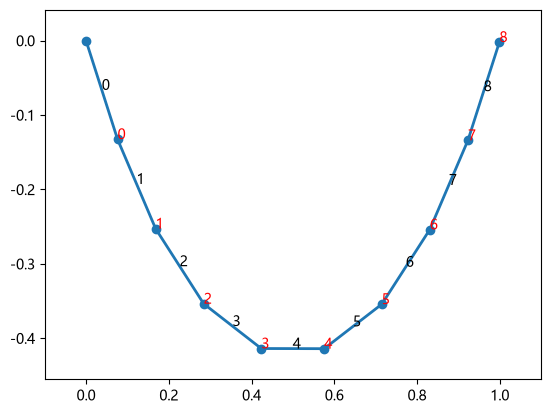

In [23]:
x = np.linspace(0, 1, 1000)
y = catenary(x, 0.35)
s = np.cumsum(np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2))
p = np.linspace(0, s[-1], 10)
idx = np.searchsorted(s, p)
x, y = x[idx], y[idx]
plt.plot(x, y, "-o", lw=2)
for i, (x1, x2, y1, y2) in enumerate(zip(x[:-1], x[1:], y[:-1], y[1:])):
    plt.text((x1 + x2) * 0.5, (y1 + y2) * 0.5, "%d" % i)
    plt.text(x2, y2, "%d" % i, color="r", fontsize=10)
plt.margins(0.1);

于是最小化问题就变成：在满足两个约束的前提下，找出让 $P$ 最小的 $\theta_i$ 的组合，其中 $\theta_i$ 的范围是 $\frac{-\pi}{2} < \theta_i < \frac{\pi}{2}$。这类带等式约束的最小化问题用 `SLSQP` 就能解。

下面程序里的 `g1()` 与 `g2()` 分别返回右端点的 x 坐标与 y 坐标应当满足的条件，返回 0 就表示约束得到满足；`P(theta)` 则是该状态下的位置能。

❶ 为了让计算更快，先让初始值满足这两个约束，图中 × 号就是那个位置。❷ `constraints` 是约束的列表，按 `minimize()` 的文档，`SLSQP` 里每个约束用字典指定：`type` 为 `'eq'` 是等式约束，为 `'ineq'` 是不等式约束，`fun` 是计算约束的函数。❸ 再用 `bounds` 指定各变量的范围。

In [24]:
N = 30

l = length / N


def g1(theta):
    return np.sum(l * np.cos(theta)) - 1.0


def g2(theta):
    return np.sum(l * np.sin(theta)) - 0.0


def P(theta):
    y = l * np.sin(theta)
    cy = np.cumsum(y)
    return np.sum(cy)


theta0 = np.arccos(1.0 / length)
theta_init = [-theta0] * (N // 2) + [theta0] * (N // 2)  #❶

res = optimize.minimize(
    P,
    theta_init,
    method="SLSQP",
    constraints=[dict(type="eq", fun=g1), dict(type="eq", fun=g2)],  #❷
    bounds=[(-np.pi / 2, np.pi / 2)] * N,  #❸
)
print(res.message, "nit =", res.nit)

Optimization terminated successfully nit = 9


很少几次迭代就找到了最优解。下面的代码由 $\theta_i$ 算出各质点的位置并画出来，蓝色曲线是悬链线公式给出的理论值。

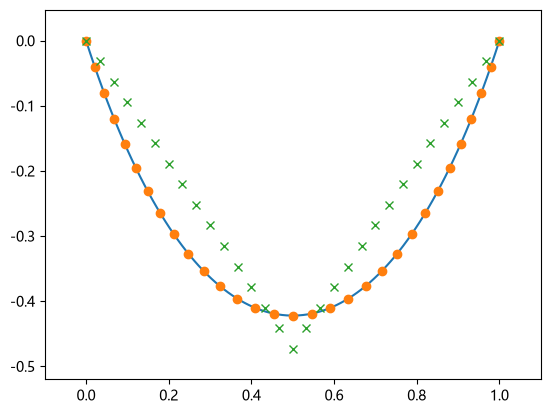

In [25]:
x_init = np.r_[0, np.cumsum(l * np.cos(theta_init))]
y_init = np.r_[0, np.cumsum(l * np.sin(theta_init))]

theta = res.x
x = np.r_[0, np.cumsum(l * np.cos(theta))]
y = np.r_[0, np.cumsum(l * np.sin(theta))]
x2 = np.linspace(0, 1, 100)
y2 = catenary(x2, 0.35)

plt.plot(x2, y2)
plt.plot(x, y, "o")
plt.plot(x_init, y_init, "x")
plt.margins(0.1)

### 求最速降线

最速降线问题是：在两点之间开一条无摩擦的沟槽，求小球从高处滚到低处所用时间最短的那条曲线。取两点高度相同这一极端情形，立刻就能看出这条曲线并不是直线。按维基百科的说法，下降高度为 $D$ 的最速降线满足下面的微分方程。

$$dx=\sqrt{\frac{y}{D-y}}dy$$

用最优化也能近似算出这条曲线：把 x 轴从 0 到 `target` 分成 `N` 等份，各点的 y 坐标 $y_i$ 作为变量，目标是让小球沿这条曲线运动的时间最短。由能量守恒，小球到达各点时的速度是 $v = \sqrt{2 g y_i}$。

小球通过每一段的平均速度用两端速度的平均来近似，线段长度取两端的距离。这样就能算出每一段所需的时间，把这些时间加起来就是整条曲线的时间。

:::{note}
这条曲线的样子与直线差得很远：起点附近很陡，越接近终点越平缓，因此小球能迅速获得速度。下面要做的，就是把这条曲线的形状用最优化算出来。
:::

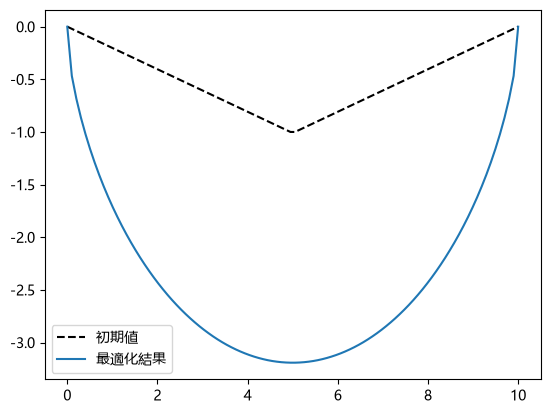

In [26]:
N = 100
target = 10.0
x = np.linspace(0, target, N)
tmp = np.linspace(0, -1, N // 2)
y0 = np.r_[tmp, tmp[::-1]]
g = 9.8


def total_time(y):
    s = np.hypot(np.diff(x), np.diff(y))  #❶
    v = np.sqrt(2 * g * np.abs(y))  #❷
    avg_v = np.maximum((v[1:] + v[:-1]) * 0.5, 1e-10)  #❸
    t = s / avg_v
    return t.sum()


def fix_two_ends(y):
    return y[[0, -1]]


res = optimize.minimize(
    total_time, y0, method="SLSQP", constraints=[dict(type="eq", fun=fix_two_ends)]
)  #❹
y_opt = res.x

plt.plot(x, y0, "k--", label="初期値")
plt.plot(x, y_opt, label="最適化結果")
plt.legend(loc="best");

❶ 用 `hypot()` 计算各线段的长度。❷ 按能量守恒的式子算出到达各点的速度。❸ 再算各线段的平均速度，由于速度为 0 时算不出时间，这里用 `maximum()` 把下限定在 $10^{-10}$。

❹ 曲线两端的 y 坐标必须保持为 0。所以这里用 `SLSQP`，并用等式约束 `fix_two_end()` 把两端固定为 0。

## 小结

* 非线性方程用 `fsolve()` 解，把雅可比矩阵传进去，在未知量很多的问题上会更快。
* 要把曲线拟合到数据上，就写一个返回误差的函数交给 `least_squares()`；一维曲线用 `curve_fit()` 更简单。
* 拟合依赖初始值，像频率这种谷很尖的参数，初始值不好就会收敛到别的解。
* 有异常值时，用 `loss="soft_l1"` 之类的损失函数配合 `f_scale` 抑制它的影响。
* 函数的极小值用 `minimize()` 找，有些算法还能用上导数或海森矩阵。
* 全局最小值用 `basinhopping()` 找。
* 带约束的问题用 `SLSQP` 配合 `constraints` 与 `bounds` 来写，折线拟合、悬链线、最速降线都属于这一类。